# Word2Vec-Based Word Embedding Analysis of Game of Thrones Text

OBJECTIVE

To preprocess textual data from Game of Thrones, train a Word2Vec model to generate word embeddings, analyze relationships between words, and visualize the learned embeddings using PCA.

In [1]:
!pip install gensim

   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
    --------------------------------------- 0.5/24.4 MB 1.4 MB/s eta 0:00:18
   - -------------------------------------- 0.8/24.4 MB 1.5 MB/s eta 0:00:16
   - -------------------------------------- 1.0/24.4 MB 1.5 MB/s eta 0:00:16
   -- ------------------------------------- 1.6/24.4 MB 1.7 MB/s eta 0:00:14
   --- ------------------------------------ 2.1/24.4 MB 1.8 MB/s eta 0:00:13
   --- ------------------------------------ 2.1/24.4 MB 1.8 MB/s eta 0:00:13
   ---- ----------------------------------- 2.6/24.4 MB 1.7 MB/s eta 0:00:14
   ---- ----------------------------------- 2.9/24.4 MB 1.7 MB/s eta 0:00:13
   ------ --------------------------------- 3.7/24.4 MB 1.8 MB/s eta 0:00:12
   ------ --------------------------------- 4.2/24.4 MB 1.9 MB/s eta 0:00:11
   ------- -------------------------------- 4.7/24.4 MB 2.0 MB/s eta 0:00:10
   --------- 

In [21]:
import gensim
from gensim.models import Word2Vec
import numpy as np 
import pandas as pd
import os

In [23]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

In [24]:
from nltk import sent_tokenize
from gensim.utils import simple_preprocess

story = []

for filename in os.listdir('game of thrones'):

    if filename.endswith('.txt'):

        f = open(os.path.join('game of thrones', filename),
                 encoding='latin-1')

        corpus = f.read()
        f.close()

        raw_sent = sent_tokenize(corpus)

        for sent in raw_sent:
          words = simple_preprocess(sent)
          words = [word for word in words if word not in stop_words]

          if words:
            story.append(words)

In [26]:
len(story)

139066

In [25]:
story[:5]

[['game',
  'thrones',
  'book',
  'one',
  'song',
  'ice',
  'fire',
  'george',
  'martin',
  'prologue',
  'start',
  'back',
  'gared',
  'urged',
  'woods',
  'began',
  'grow',
  'dark',
  'around'],
 ['wildlings', 'dead'],
 ['dead', 'frighten'],
 ['ser', 'waymar', 'royce', 'asked', 'hint', 'smile'],
 ['gared', 'rise', 'bait']]

In [27]:
story[0]

['game',
 'thrones',
 'book',
 'one',
 'song',
 'ice',
 'fire',
 'george',
 'martin',
 'prologue',
 'start',
 'back',
 'gared',
 'urged',
 'woods',
 'began',
 'grow',
 'dark',
 'around']

In [28]:
model = gensim.models.Word2Vec(window=10,min_count=2,workers=4)

In [29]:
model.build_vocab(story)

In [30]:
model.train(story,total_examples=model.corpus_count,epochs=model.epochs)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


(4395910, 4579390)

In [31]:
model.wv.most_similar('jon')

[('sam', 0.715827465057373),
 ('theon', 0.68373042345047),
 ('edd', 0.6668849587440491),
 ('ygritte', 0.6587591171264648),
 ('tormund', 0.6577381491661072),
 ('grenn', 0.6531998515129089),
 ('dolorous', 0.6418624520301819),
 ('ghost', 0.6396492123603821),
 ('mance', 0.6304630637168884),
 ('pyp', 0.6241774559020996)]

In [32]:
model.wv.doesnt_match(['queen','prince','dragon','king'])

'dragon'

In [33]:
model.wv.similarity('tyrion','jon')

np.float32(0.27552608)

In [44]:
model.wv.get_normed_vectors()

array([[ 0.0083089 ,  0.0782057 , -0.03801653, ..., -0.07810385,
        -0.10045432,  0.1785031 ],
       [-0.20109954,  0.13243936,  0.11128987, ..., -0.05053236,
        -0.08537809,  0.19670467],
       [-0.04840714,  0.01980807, -0.01831271, ..., -0.17872381,
         0.09711891, -0.14552213],
       ...,
       [-0.0954758 , -0.06852333, -0.04378527, ..., -0.06883717,
         0.06043099,  0.09113768],
       [-0.15990432,  0.03847293,  0.16447268, ..., -0.16086477,
         0.13944271,  0.03782243],
       [-0.04260451,  0.02039408,  0.1710745 , ..., -0.03561669,
         0.03635731, -0.12120573]], shape=(17310, 100), dtype=float32)

In [36]:
model.wv['daenerys'].shape

(100,)

PCA visualization

PCA is used to reduce the high-dimensional Word2Vec embeddings to two dimensions so that relationships between words can be visualized.

In [41]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [46]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)

X = pca.fit_transform(model.wv.get_normed_vectors())

print(X.shape)

(17310, 3)


In [48]:
X[:5]

array([[ 0.49394152,  0.00928226,  0.23075666],
       [ 0.39167362,  0.54887724,  0.40118518],
       [ 0.51144123, -0.05129406, -0.31339082],
       [-0.01678491,  0.14202885,  0.00546684],
       [ 0.2864607 ,  0.49315667,  0.5602201 ]], dtype=float32)

In [49]:
X.shape

(17310, 3)

In [47]:
y = model.wv.index_to_key

print(len(y))
print(y[:10])

17310
['said', 'lord', 'would', 'one', 'ser', 'could', 'man', 'king', 'men', 'back']


In [53]:
print(X.shape)
print(len(y))

(17310, 3)
17310


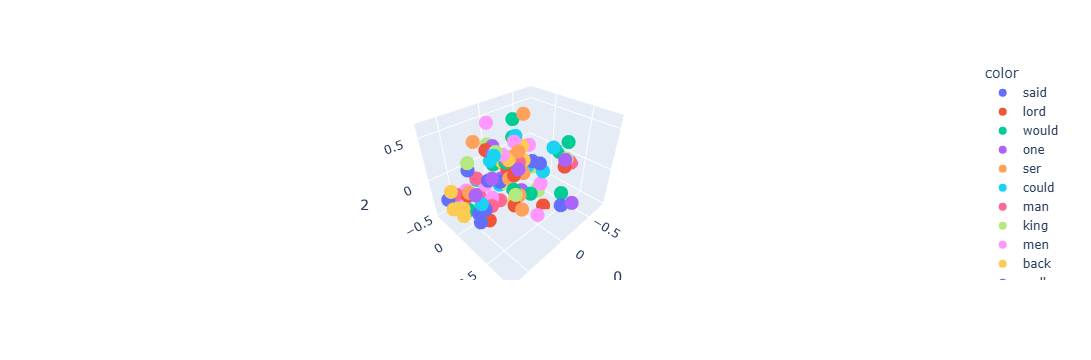

In [50]:
import plotly.express as px

fig = px.scatter_3d(X[:100], x=0, y=1, z=2, color=y[:100])
fig.show()



Conclusion
The Word2Vec model successfully learned vector representations of words from the Game of Thrones text corpus. After preprocessing and removing stop words, the model was trained to identify contextually similar words and compare relationships between them. PCA was used to reduce the dimensionality of the word embeddings and visualize their relationships in two dimensions.